In [1]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import os

from torchvision import datasets, transforms

# GitHub için görsellerin kaydedileceği klasör
os.makedirs("images", exist_ok=True)

Görüntü boyutu: (1488, 1047, 3)


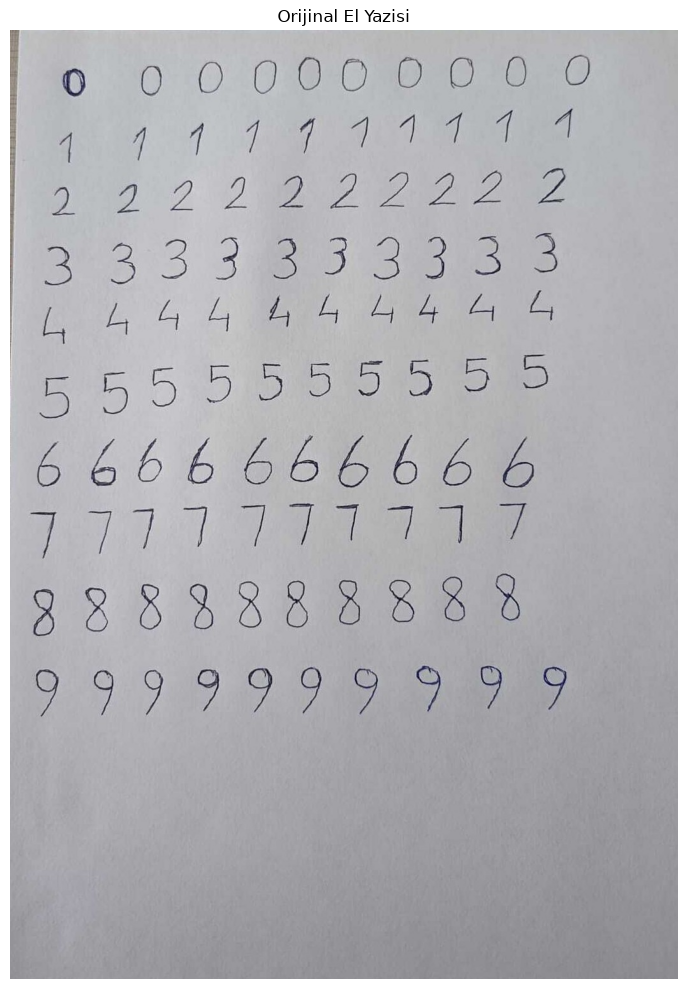

In [2]:
img = cv2.imread("el_yazisi.jpg")

if img is None:
    raise FileNotFoundError("Fotoğraf bulunamadı!")

print("Görüntü boyutu:", img.shape)

plt.figure(figsize=(8, 10))

plt.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
plt.title("Orijinal El Yazisi")
plt.axis("off")

plt.tight_layout()
plt.savefig("images/01_original.png", dpi=300)
plt.show()

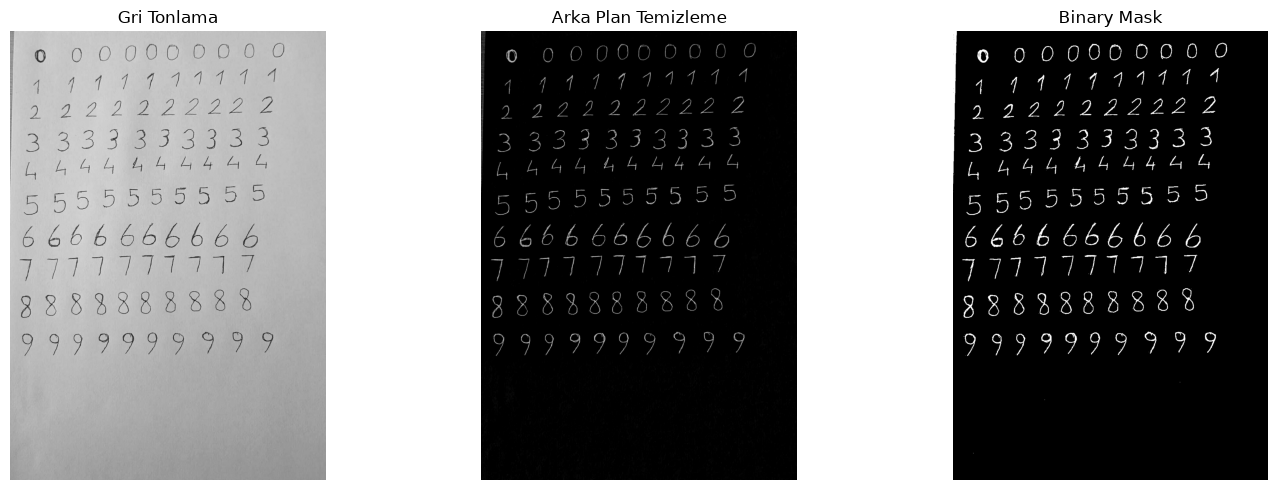

In [3]:
# Gri tonlama
gray = cv2.cvtColor(
    img,
    cv2.COLOR_BGR2GRAY
)

# Arka plan tahmini
background = cv2.GaussianBlur(
    gray,
    (0, 0),
    sigmaX=25
)

# Koyu rakamları ön plana çıkar
foreground = cv2.subtract(
    background,
    gray
)

# Binary maske
mask = (foreground > 12).astype(np.uint8) * 255

fig, axes = plt.subplots(1, 3, figsize=(15, 5))

axes[0].imshow(gray, cmap="gray")
axes[0].set_title("Gri Tonlama")

axes[1].imshow(foreground, cmap="gray")
axes[1].set_title("Arka Plan Temizleme")

axes[2].imshow(mask, cmap="gray")
axes[2].set_title("Binary Mask")

for ax in axes:
    ax.axis("off")

plt.tight_layout()

plt.savefig(
    "images/02_preprocessing.png",
    dpi=300
)

plt.show()

In [4]:
num_labels, component_labels, stats, centroids = (
    cv2.connectedComponentsWithStats(
        mask,
        connectivity=8
    )
)

boxes = []

for i in range(1, num_labels):

    x, y, w, h, area = stats[i]

    if (
        area > 20
        and 5 < w < 100
        and 10 < h < 120
    ):
        boxes.append((x, y, w, h))

print("Tespit edilen rakam sayısı:", len(boxes))

Tespit edilen rakam sayısı: 100


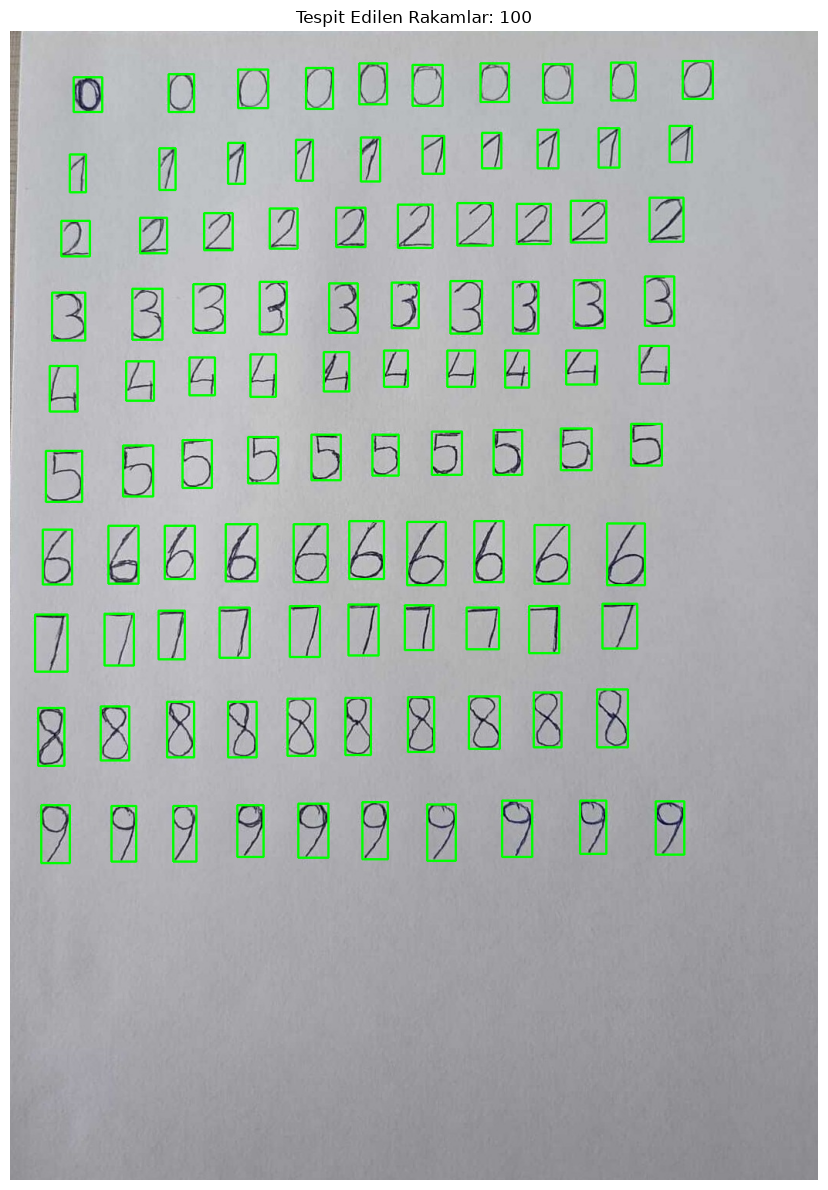

In [5]:
img_boxes = img.copy()

for x, y, w, h in boxes:

    cv2.rectangle(
        img_boxes,
        (x, y),
        (x + w, y + h),
        (0, 255, 0),
        2
    )

plt.figure(figsize=(10, 12))

plt.imshow(
    cv2.cvtColor(img_boxes, cv2.COLOR_BGR2RGB)
)

plt.title(f"Tespit Edilen Rakamlar: {len(boxes)}")
plt.axis("off")

plt.tight_layout()
plt.savefig("images/03_detected_digits.png", dpi=300)
plt.show()

In [6]:
if len(boxes) != 100:
    raise ValueError(
        f"100 rakam bekleniyordu, {len(boxes)} bulundu."
    )

# Önce yukarıdan aşağıya sırala
boxes.sort(
    key=lambda b: b[1] + b[3] / 2
)

sorted_boxes = []

# Her satırdaki 10 rakamı soldan sağa sırala
for row in range(10):

    row_boxes = boxes[
        row * 10:(row + 1) * 10
    ]

    row_boxes.sort(key=lambda b: b[0])

    sorted_boxes.extend(row_boxes)

boxes = sorted_boxes

print("Rakamlar sıralandı.")

Rakamlar sıralandı.


In [7]:
digits = []

for x, y, w, h in boxes:

    # Rakamı gri tonlamalı görüntüden kırp
    digit = foreground[
        y:y+h,
        x:x+w
    ].astype(np.float32)

    # Kontrastı artır
    digit = np.clip(
        (digit - 6.0) * 5.0,
        0,
        255
    ).astype(np.uint8)

    # En-boy oranını koruyarak küçült
    scale = 20 / max(w, h)

    new_w = max(1, round(w * scale))
    new_h = max(1, round(h * scale))

    resized = cv2.resize(
        digit,
        (new_w, new_h),
        interpolation=cv2.INTER_AREA
        if scale < 1 else cv2.INTER_LINEAR
    )

    # 28x28 siyah arka plan
    canvas = np.zeros(
        (28, 28),
        dtype=np.uint8
    )

    offset_x = (28 - new_w) // 2
    offset_y = (28 - new_h) // 2

    canvas[
        offset_y:offset_y+new_h,
        offset_x:offset_x+new_w
    ] = resized

    digits.append(canvas)

print("Hazırlanan rakam:", len(digits))
print("Görüntü boyutu:", digits[0].shape)

Hazırlanan rakam: 100
Görüntü boyutu: (28, 28)


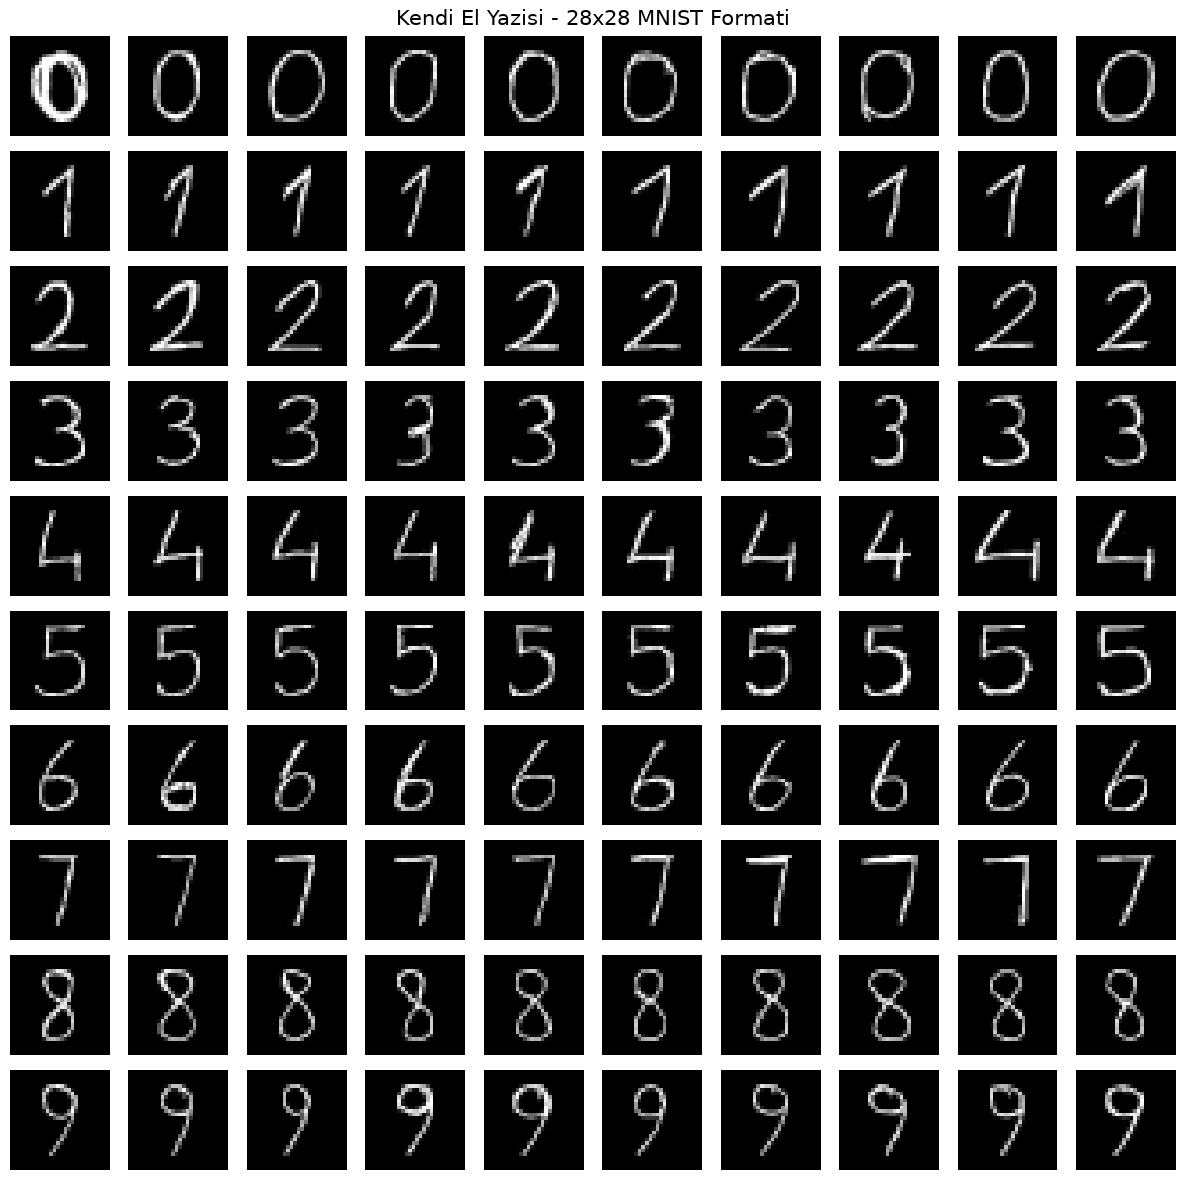

In [8]:
fig, axes = plt.subplots(
    10, 10,
    figsize=(12, 12)
)

for i, ax in enumerate(axes.flat):

    ax.imshow(
        digits[i],
        cmap="gray",
        vmin=0,
        vmax=255,
        interpolation="nearest"
    )

    ax.axis("off")

plt.suptitle(
    "Kendi El Yazisi - 28x28 MNIST Formati",
    fontsize=15
)

plt.tight_layout()
plt.savefig(
    "images/04_processed_digits.png",
    dpi=300
)
plt.show()

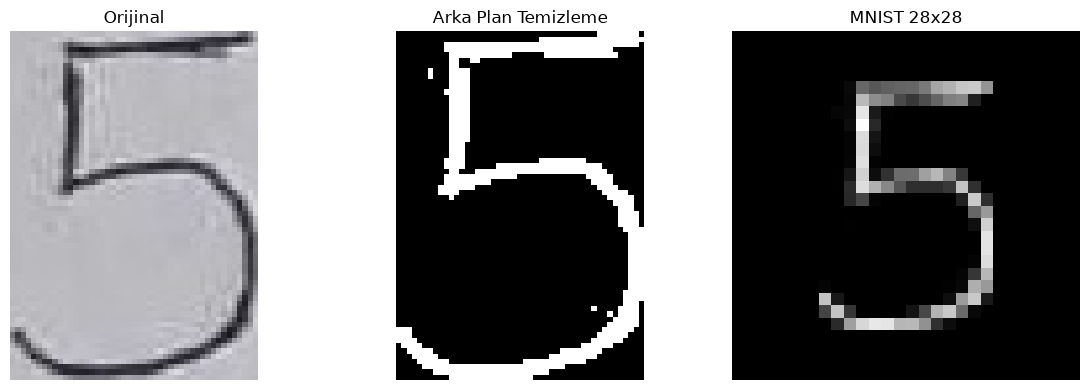

In [9]:
rakam = 5
ornek = 0

index = rakam * 10 + ornek

x, y, w, h = boxes[index]

original = img[y:y+h, x:x+w]
binary = mask[y:y+h, x:x+w]
processed = digits[index]

fig, axes = plt.subplots(
    1, 3,
    figsize=(12, 4)
)

axes[0].imshow(
    cv2.cvtColor(original, cv2.COLOR_BGR2RGB)
)
axes[0].set_title("Orijinal")

axes[1].imshow(
    binary,
    cmap="gray",
    vmin=0,
    vmax=255
)
axes[1].set_title("Arka Plan Temizleme")

axes[2].imshow(
    processed,
    cmap="gray",
    vmin=0,
    vmax=255,
    interpolation="nearest"
)
axes[2].set_title("MNIST 28x28")

for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.savefig(
    "images/05_preprocessing_example.png",
    dpi=300
)
plt.show()

In [10]:
class MLP(nn.Module):

    def __init__(self):
        super().__init__()

        self.flatten = nn.Flatten()

        self.fc1 = nn.Linear(784, 128)
        self.fc2 = nn.Linear(128, 64)
        self.fc3 = nn.Linear(64, 10)

        self.relu = nn.ReLU()

    def forward(self, x):

        x = self.flatten(x)

        x = self.relu(self.fc1(x))
        x = self.relu(self.fc2(x))

        x = self.fc3(x)

        return x


device = torch.device("cpu")

model = MLP().to(device)

model.load_state_dict(
    torch.load(
        "best_mlp.pth",
        map_location=device,
        weights_only=True
    )
)

model.eval()

print("Eğitilmiş MLP modeli yüklendi.")

Eğitilmiş MLP modeli yüklendi.


In [11]:
# Normalizasyon: [0, 255] -> [0, 1]
X = np.stack(digits).astype(np.float32) / 255.0

# PyTorch tensörü
X = torch.from_numpy(X).unsqueeze(1).to(device)

# Gerçek etiketler
true_labels = np.repeat(np.arange(10), 10)

with torch.no_grad():

    outputs = model(X)

    predictions = outputs.argmax(
        dim=1
    ).cpu().numpy()

correct = np.sum(
    predictions == true_labels
)

handwriting_accuracy = (
    100 * correct / len(true_labels)
)

print(f"El Yazısı Accuracy: %{handwriting_accuracy:.2f}")
print(f"Doğru Tahmin: {correct}/100")

El Yazısı Accuracy: %79.00
Doğru Tahmin: 79/100


In [12]:
digit_accuracies = []

for digit in range(10):

    start = digit * 10
    end = start + 10

    digit_correct = np.sum(
        predictions[start:end] == digit
    )

    accuracy = 100 * digit_correct / 10

    digit_accuracies.append(accuracy)

    print(
        f"Rakam {digit}: "
        f"{digit_correct}/10 doğru "
        f"(%{accuracy:.0f})"
    )

Rakam 0: 10/10 doğru (%100)
Rakam 1: 2/10 doğru (%20)
Rakam 2: 10/10 doğru (%100)
Rakam 3: 10/10 doğru (%100)
Rakam 4: 10/10 doğru (%100)
Rakam 5: 10/10 doğru (%100)
Rakam 6: 9/10 doğru (%90)
Rakam 7: 4/10 doğru (%40)
Rakam 8: 10/10 doğru (%100)
Rakam 9: 4/10 doğru (%40)


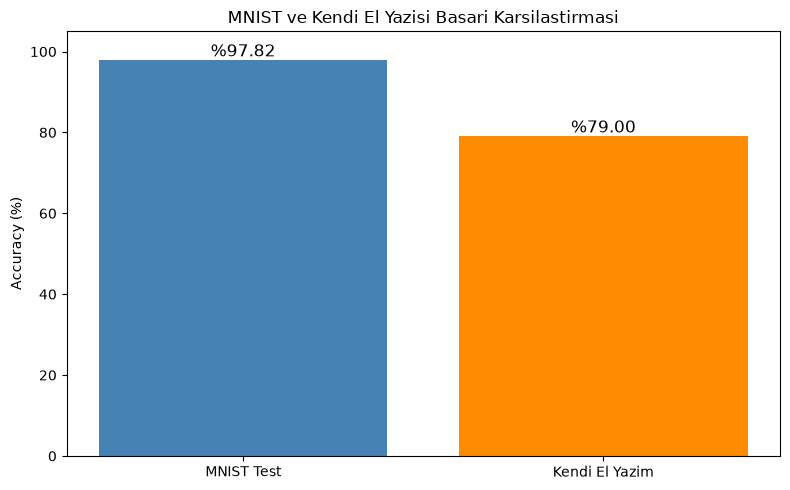

In [13]:
mnist_accuracy = 97.82

labels = [
    "MNIST Test",
    "Kendi El Yazim"
]

values = [
    mnist_accuracy,
    handwriting_accuracy
]

plt.figure(figsize=(8, 5))

bars = plt.bar(
    labels,
    values,
    color=["steelblue", "darkorange"]
)

plt.ylim(0, 105)
plt.ylabel("Accuracy (%)")

plt.title(
    "MNIST ve Kendi El Yazisi Basari Karsilastirmasi"
)

for bar, value in zip(bars, values):

    plt.text(
        bar.get_x() + bar.get_width()/2,
        value + 1,
        f"%{value:.2f}",
        ha="center",
        fontsize=12
    )

plt.tight_layout()
plt.savefig(
    "images/06_accuracy_comparison.png",
    dpi=300
)
plt.show()

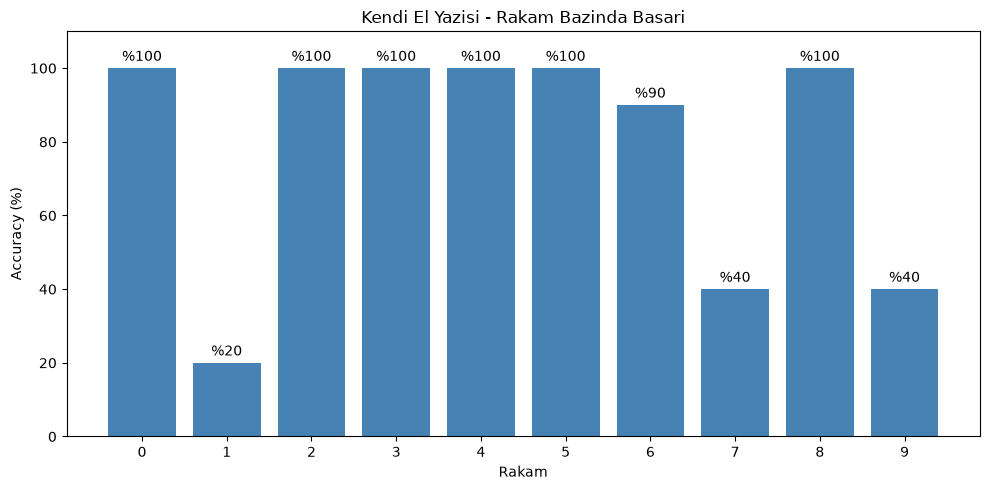

In [14]:
plt.figure(figsize=(10, 5))

bars = plt.bar(
    range(10),
    digit_accuracies,
    color="steelblue"
)

plt.xlabel("Rakam")
plt.ylabel("Accuracy (%)")

plt.title(
    "Kendi El Yazisi - Rakam Bazinda Basari"
)

plt.xticks(range(10))
plt.ylim(0, 110)

for bar, acc in zip(bars, digit_accuracies):

    plt.text(
        bar.get_x() + bar.get_width()/2,
        acc + 2,
        f"%{acc:.0f}",
        ha="center"
    )

plt.tight_layout()
plt.savefig(
    "images/07_digit_accuracy.png",
    dpi=300
)
plt.show()

In [15]:
transform = transforms.ToTensor()

mnist_train = datasets.MNIST(
    root="./data",
    train=True,
    download=True,
    transform=transform
)

print("MNIST hazır.")

MNIST hazır.


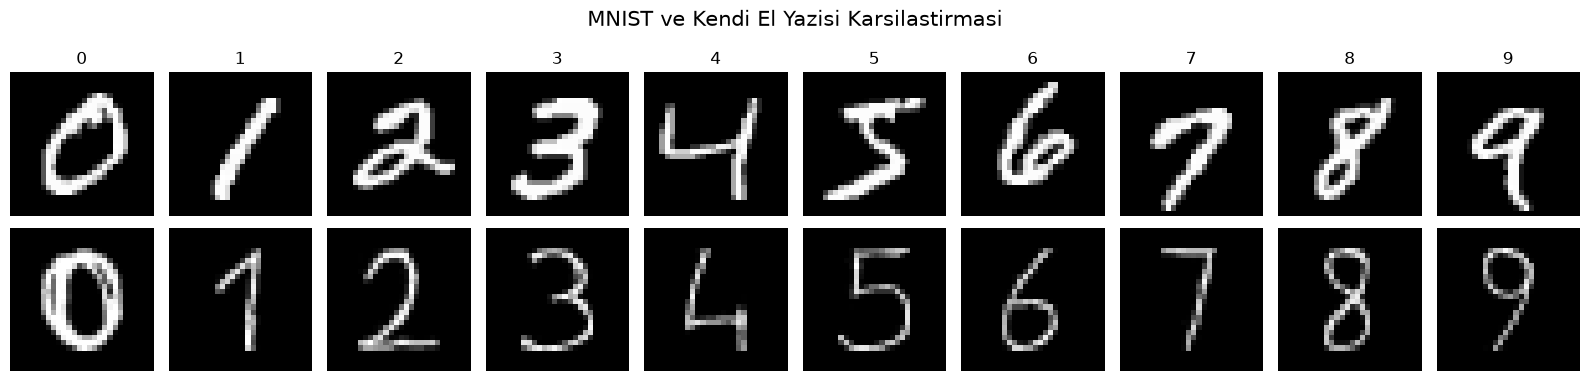

In [16]:
fig, axes = plt.subplots(
    2, 10,
    figsize=(16, 4)
)

for digit in range(10):

    # MNIST içerisinden aynı rakamı bul
    idx = torch.where(
        mnist_train.targets == digit
    )[0][0].item()

    mnist_img, _ = mnist_train[idx]

    # Kendi el yazımızdan ilk örnek
    my_img = digits[digit * 10]

    axes[0, digit].imshow(
        mnist_img.squeeze(),
        cmap="gray",
        vmin=0,
        vmax=1,
        interpolation="nearest"
    )

    axes[1, digit].imshow(
        my_img,
        cmap="gray",
        vmin=0,
        vmax=255,
        interpolation="nearest"
    )

    axes[0, digit].set_title(str(digit))

    axes[0, digit].axis("off")
    axes[1, digit].axis("off")

axes[0, 0].set_ylabel("MNIST", fontsize=12)
axes[1, 0].set_ylabel("El Yazim", fontsize=12)

plt.suptitle(
    "MNIST ve Kendi El Yazisi Karsilastirmasi",
    fontsize=15
)

plt.tight_layout()
plt.savefig(
    "images/08_mnist_vs_handwriting.png",
    dpi=300
)
plt.show()

Yanlış tahmin: 21


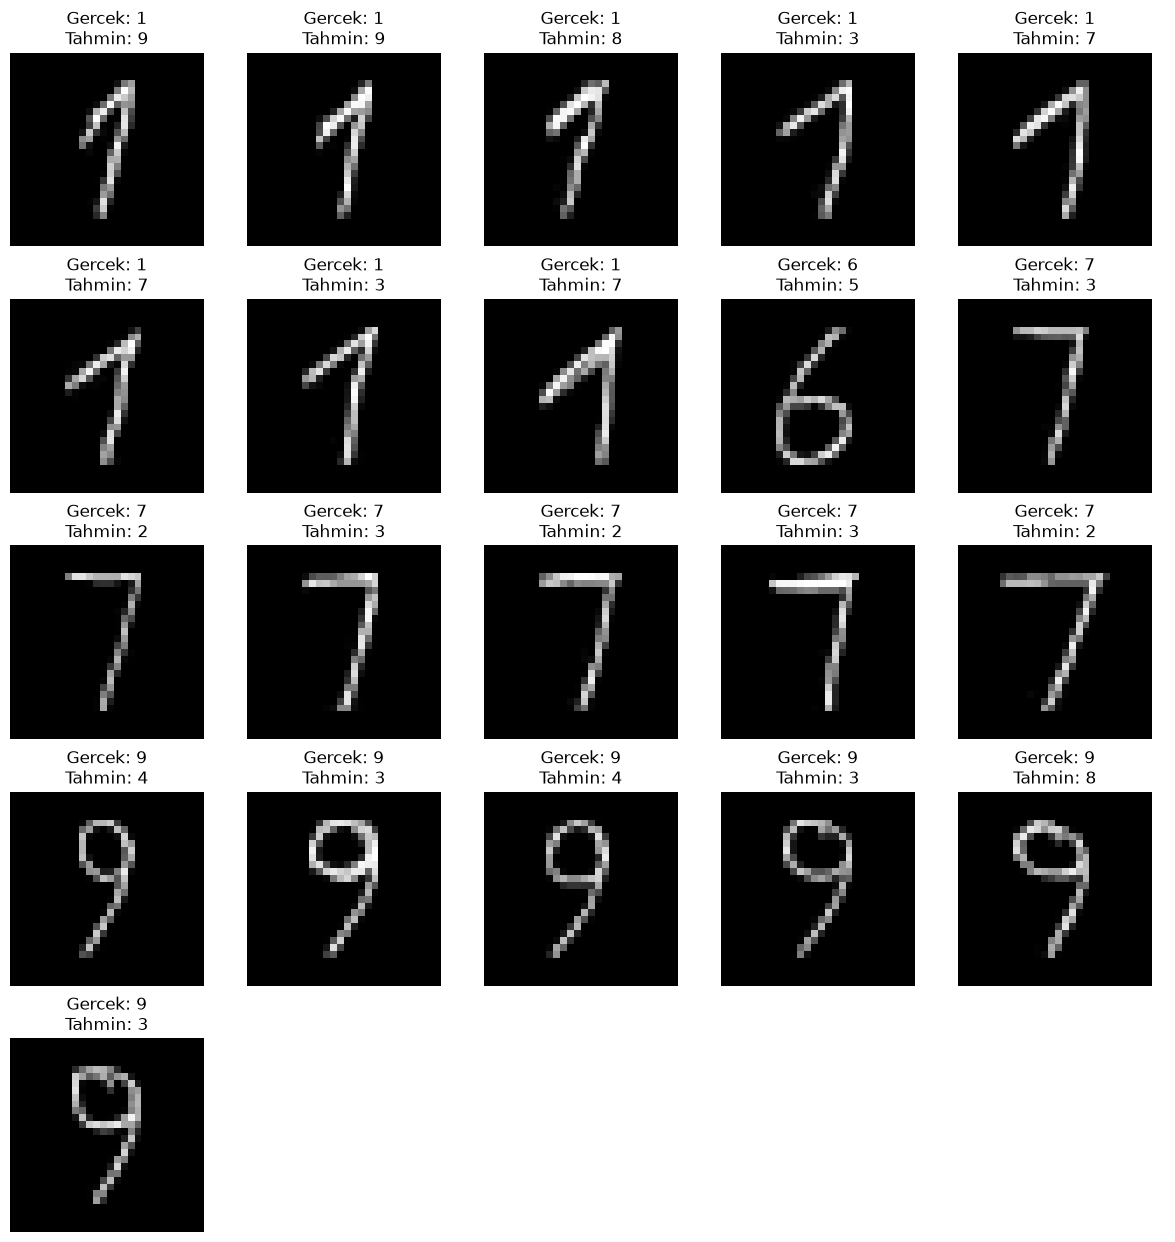

In [17]:
wrong_indices = np.where(
    predictions != true_labels
)[0]

print("Yanlış tahmin:", len(wrong_indices))

if len(wrong_indices) > 0:

    cols = 5
    rows = int(np.ceil(len(wrong_indices) / cols))

    fig, axes = plt.subplots(
        rows,
        cols,
        figsize=(12, rows * 2.5),
        squeeze=False
    )

    for ax in axes.flat:
        ax.axis("off")

    for ax, idx in zip(axes.flat, wrong_indices):

        ax.imshow(
            digits[idx],
            cmap="gray",
            vmin=0,
            vmax=255,
            interpolation="nearest"
        )

        ax.set_title(
            f"Gercek: {true_labels[idx]}\n"
            f"Tahmin: {predictions[idx]}"
        )

        ax.axis("off")

    plt.tight_layout()
    plt.savefig(
        "images/09_wrong_predictions.png",
        dpi=300
    )
    plt.show()